In [1]:
%matplotlib widget
import importlib
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import pandas as pd
import io
import matplotlib
import scipy as sc


os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\COMSOL\Acoustic')
import Treat_acoustic_func as Treat_acoustic_func
importlib.reload(Treat_acoustic_func)
from Treat_acoustic_func import *


os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\COMSOL\Acoustic')
import Treat_acoustic_plotting as Treat_acoustic_plotting
importlib.reload(Treat_acoustic_plotting)
from Treat_acoustic_plotting import *




fontsize=30
import matplotlib as mpl
mpl.rcParams["font.size"] = 18

In [2]:
dir_root = r'H:\commun\Utilisateur FNO\Nathan\COMSOL\AuND\Acoustic\Sapphire\Intermediate geometry\r_corner_sweep\AR1.5_2.5'


Shape_choice = 'cylinder'
R_corner_list = ['1_nm', '2_nm', '3_nm', '4_nm', '5_nm', '6_nm', '7_nm', '8_nm', '9_nm']

Spectra_data = {}
Colors = {}
compt=0

cm = plt.get_cmap('gist_rainbow')
cm = plt.get_cmap('Reds')
Colors_list = [matplotlib.colors.to_hex(cm(1.*i/np.size(R_corner_list))) for i in range(np.size(R_corner_list))]


for r_corner in R_corner_list :
    Colors[r_corner] = Colors_list[compt]
    compt +=1
    dir_spectra= dir_root
    Fname_list = ['size_sweep_AR_1.5_8_r_corner_' + r_corner]
    Spectra_data[r_corner]= get_raw_size_sweep_data_Nathan(dir_spectra, Fname_list, verbose=False)

Total size of raw data : 3280
Total size of raw data : 3280
Total size of raw data : 3280
Total size of raw data : 3280
Total size of raw data : 3280
Total size of raw data : 3280
Total size of raw data : 3280
Total size of raw data : 3280
Total size of raw data : 6480


In [3]:
#plot_all_raw_spectra_interactive(Spectra_cylinder)

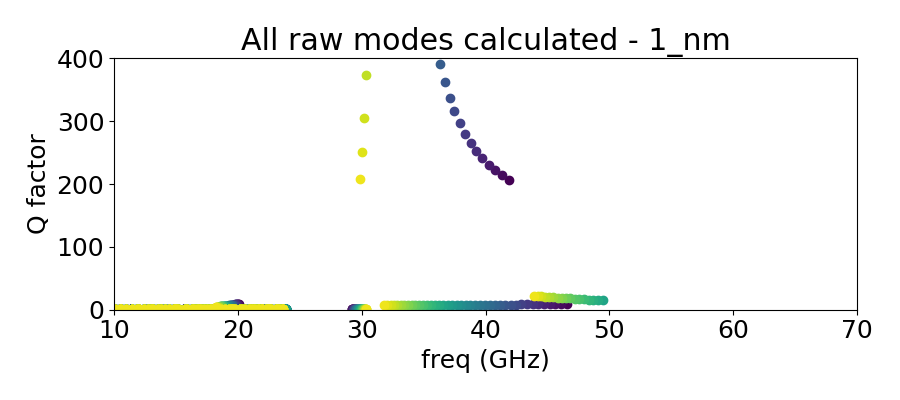

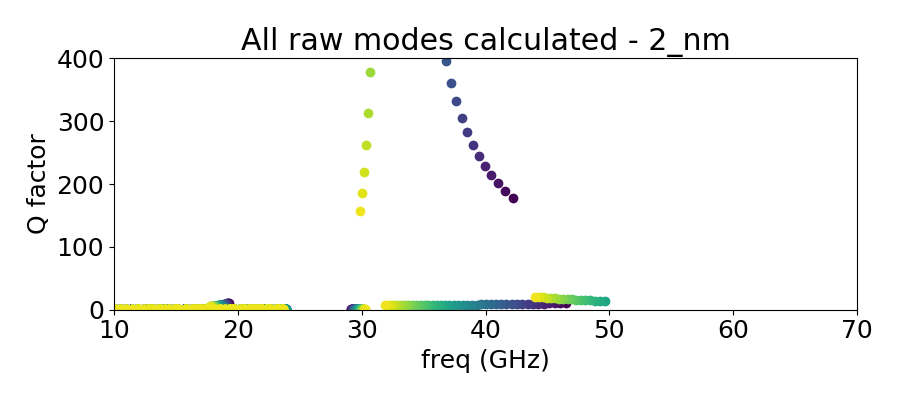

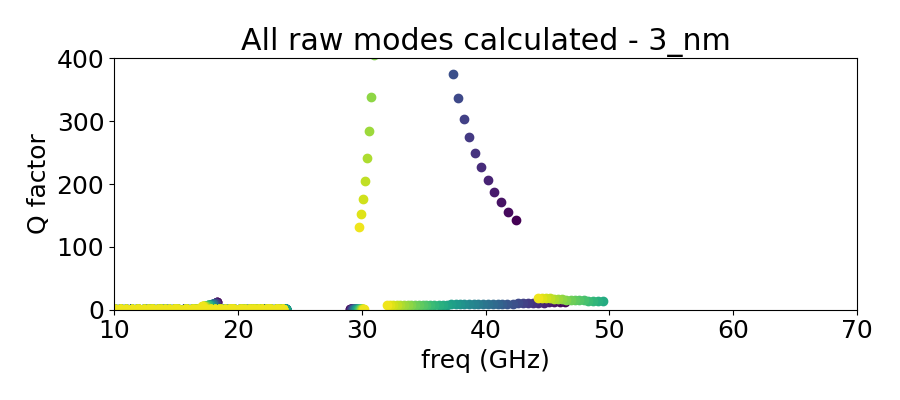

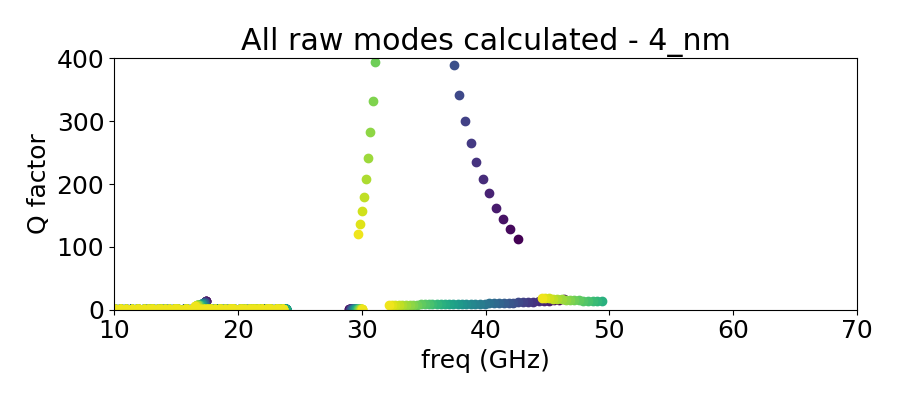

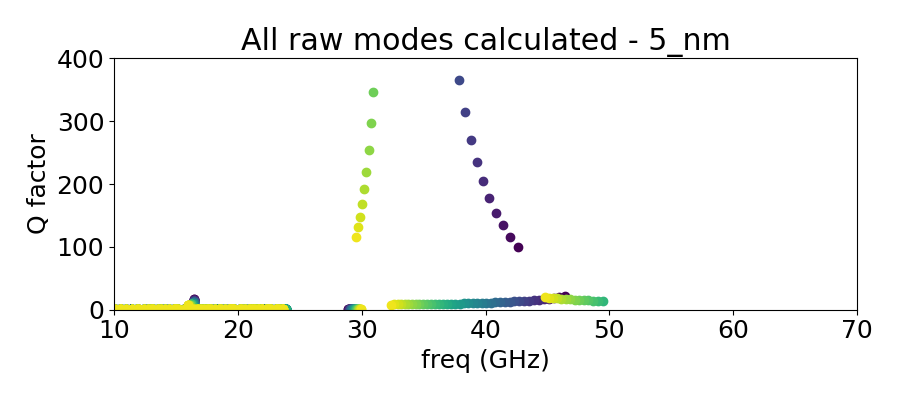

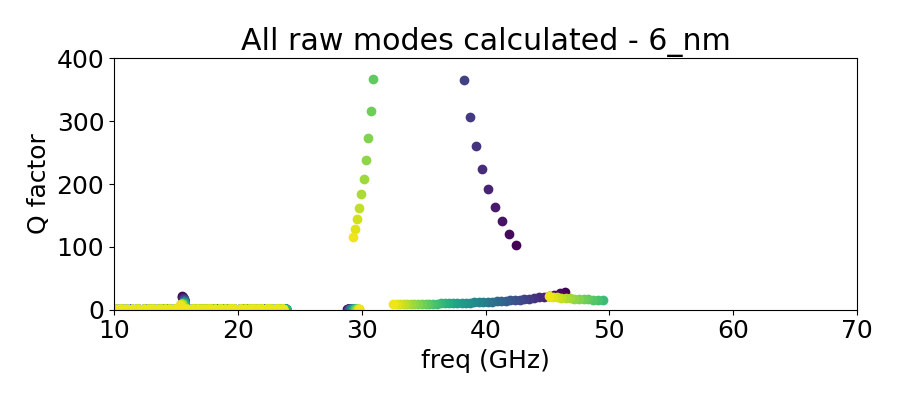

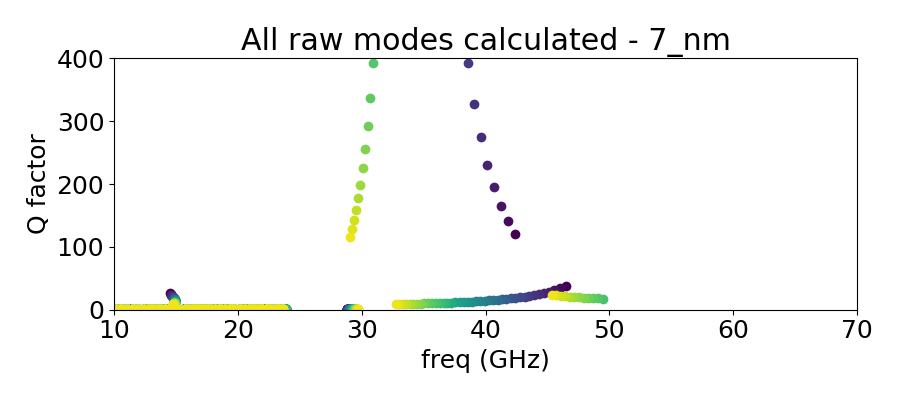

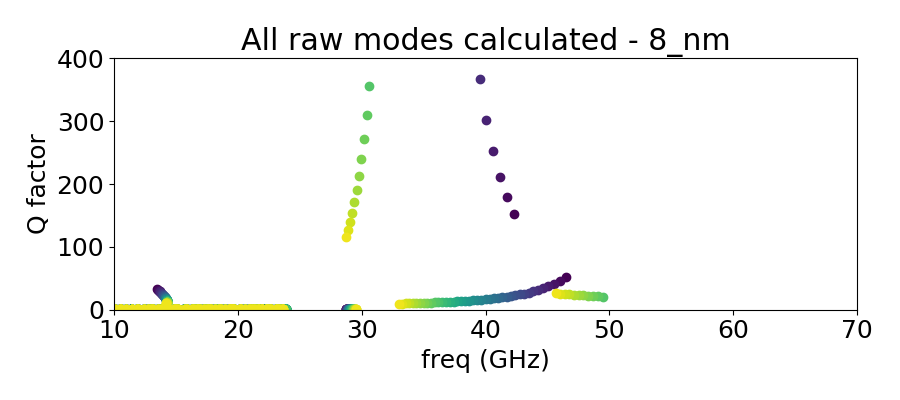

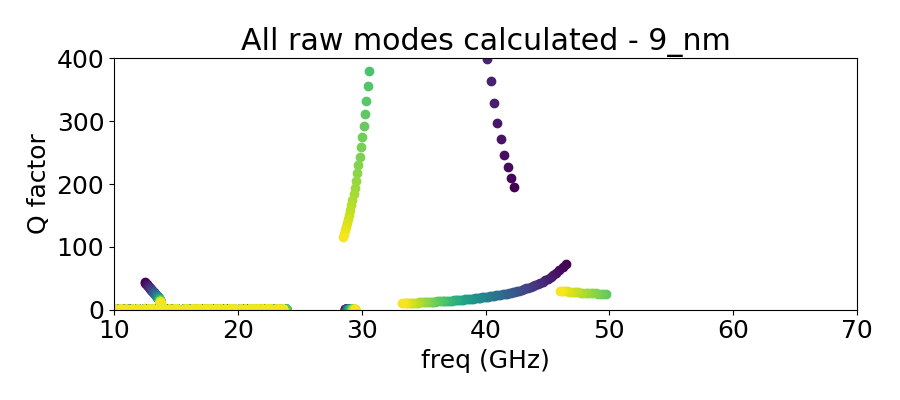

In [4]:
bottom = 0
top=400
xlim = (10, 70)

for key in Spectra_data :
    spectra = Spectra_data[key]

    fig, ax = plt.subplots(figsize = (9,4))

    plot_all_raw_spectra(spectra, ax, plotted_key = 'Q')

    ax.set_xlabel('freq (GHz)')
    ax.set_ylabel('Q factor')
    ax.set_ylim(bottom=bottom )
    ax.set_ylim( top=top)
    ax.set_xlim(xlim)
    ax.set_title('All raw modes calculated - ' + key)
    #plt.legend(fontsize=10)
    plt.tight_layout()

In [5]:
for key in Spectra_data :
    spectra = Spectra_data[key]
    get_modes_with_Q_selection(spectra, Q_th=1)

## def freq limit functions to extract Q factor

In [6]:
## For cylinder

def f1_low(ar) :
    return(38/(ar**0.5))

def f1_high(ar) :
    return(60/(ar**0.48))

## For round corner

def f2_low(ar) :
    return(35/(ar**0.5))

def f2_high(ar) :
    return(60/(ar**0.48))


## For round
def f3_low(ar) :
    return(34/(ar**0.5))

def f3_high(ar) :
    return(60/(ar**0.48))

## For round
def f4_low(ar) :
    return(33/(ar**0.5))

def f4_high(ar) :
    return(60/(ar**0.48))

## For round
def f5_low(ar) :
    return(32.3/(ar**0.5))

def f5_high(ar) :
    return(60/(ar**0.48))


mode_crossing_1 = True

Modes_dic={}
Modes_dic['0_nm']={}
Modes_dic['0_nm']['AR_crossing'] = 2.84
Modes_dic['0_nm']['Crossing'] = mode_crossing_1
Modes_dic['1_nm']={}
Modes_dic['1_nm']['AR_crossing'] = 2.85
Modes_dic['1_nm']['Crossing'] = mode_crossing_1
Modes_dic['2_nm']={}
Modes_dic['2_nm']['AR_crossing'] = 2.85
Modes_dic['2_nm']['Crossing'] = mode_crossing_1
Modes_dic['3_nm']={}
Modes_dic['3_nm']['AR_crossing'] = 2.85
Modes_dic['3_nm']['Crossing'] = mode_crossing_1
Modes_dic['4_nm']={}
Modes_dic['4_nm']['AR_crossing'] = 2.85
Modes_dic['4_nm']['Crossing'] = mode_crossing_1
Modes_dic['5_nm']={}
Modes_dic['5_nm']['AR_crossing'] = 2.95
Modes_dic['5_nm']['Crossing'] = mode_crossing_1
Modes_dic['6_nm']={}
Modes_dic['6_nm']['AR_crossing'] = 2.95
Modes_dic['6_nm']['Crossing'] = mode_crossing_1
Modes_dic['7_nm']={}
Modes_dic['7_nm']['AR_crossing'] = 2.95
Modes_dic['7_nm']['Crossing'] = mode_crossing_1
Modes_dic['8_nm']={}
Modes_dic['8_nm']['AR_crossing'] = 2.95
Modes_dic['8_nm']['Crossing'] = mode_crossing_1
Modes_dic['9_nm']={}
Modes_dic['9_nm']['AR_crossing'] = 2.95
Modes_dic['9_nm']['Crossing'] = mode_crossing_1
Modes_dic['10_nm']={}
Modes_dic['10_nm']['AR_crossing'] = 2.95
Modes_dic['10_nm']['Crossing'] = mode_crossing_1


Boundary_func = {}
Boundary_func['0_nm'] = (f1_low, f1_high)
Boundary_func['1_nm'] = (f1_low, f1_high)
Boundary_func['2_nm'] = (f2_low, f2_high)
Boundary_func['3_nm'] = (f2_low, f2_high)
Boundary_func['4_nm'] = (f2_low, f2_high)
Boundary_func['5_nm'] = (f2_low, f2_high)
Boundary_func['6_nm'] = (f2_low, f2_high)
Boundary_func['7_nm'] = (f3_low, f3_high)
Boundary_func['8_nm'] = (f3_low, f3_high)
Boundary_func['9_nm'] = (f4_low, f4_high)
Boundary_func['10_nm'] = (f5_low, f5_high)

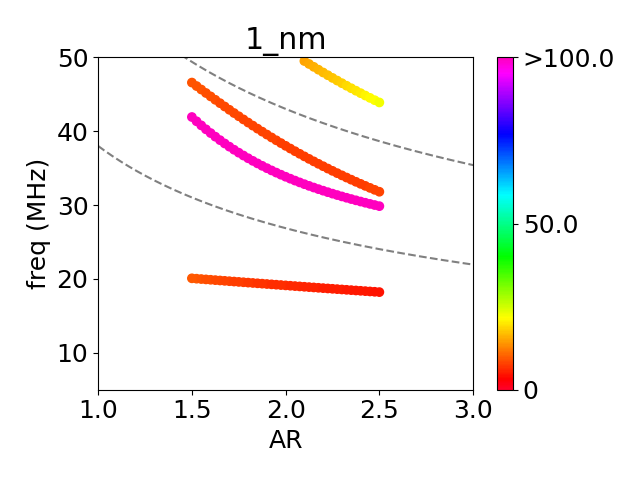

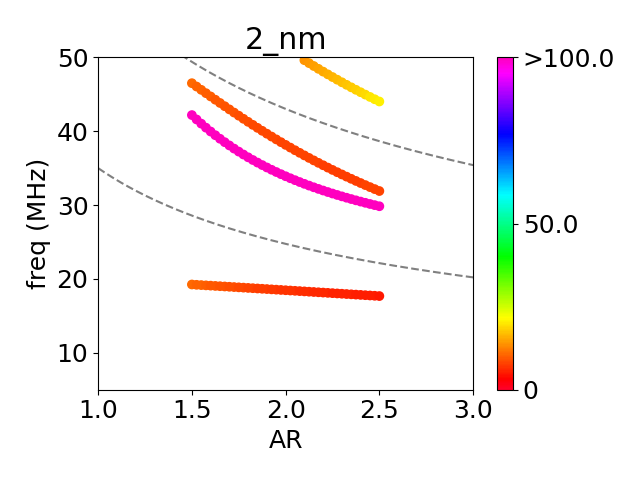

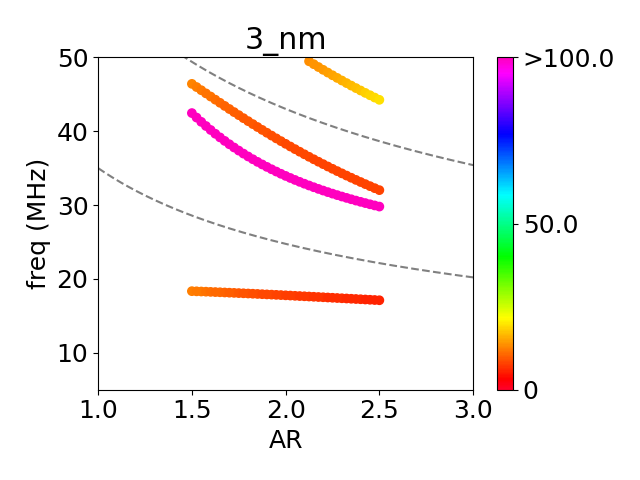

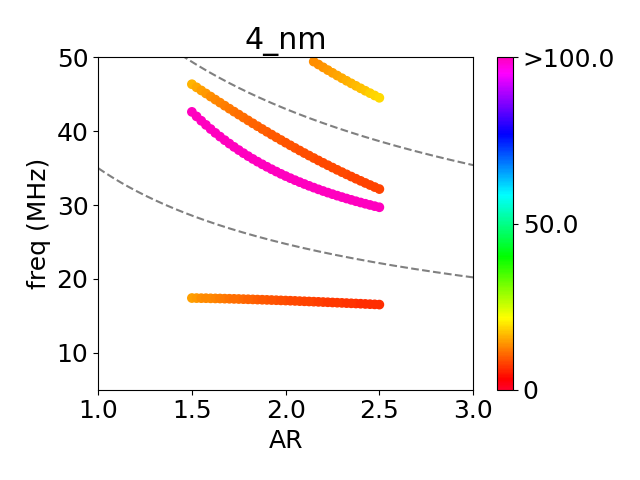

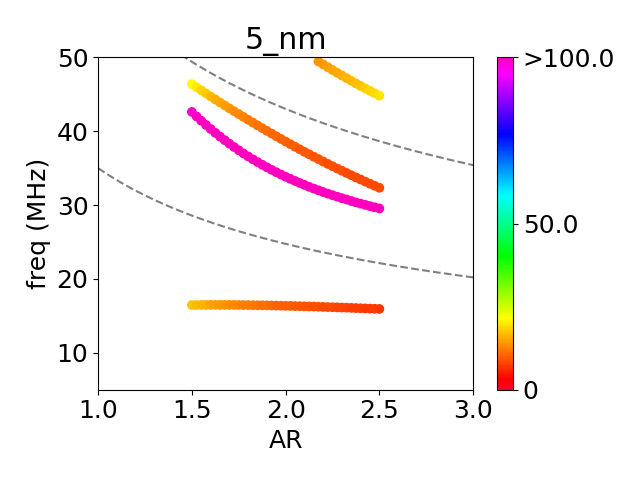

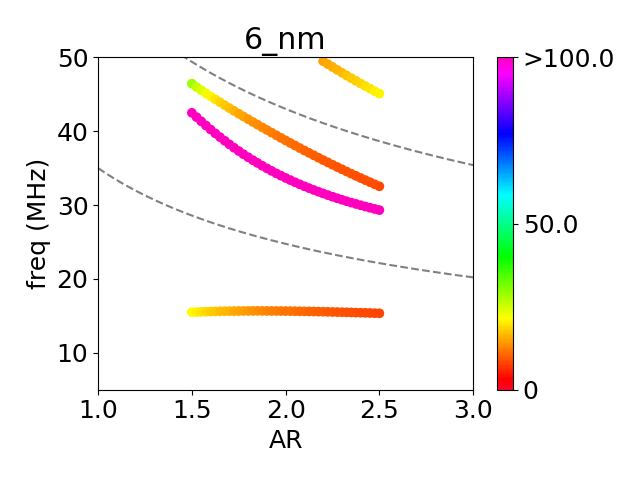

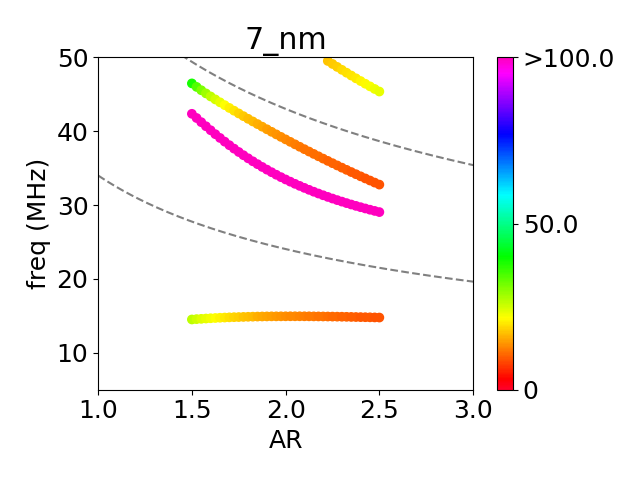

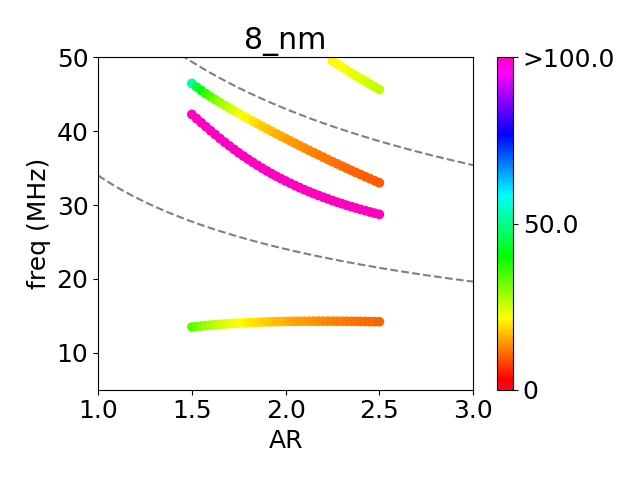

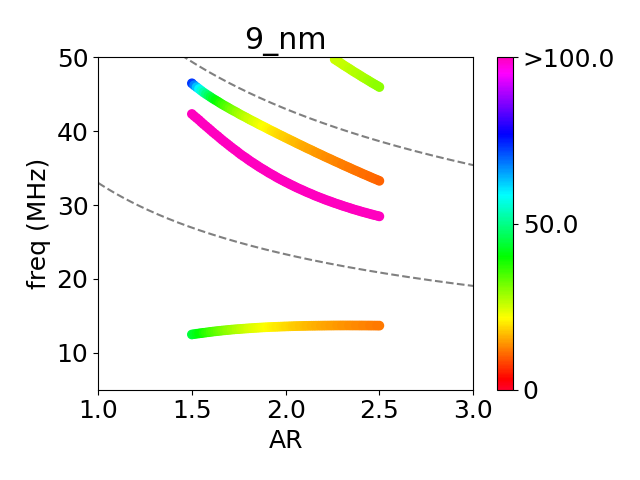

In [7]:
Q_max = 100
xlim = (1, 3)
ylim = (5, 50)
AR_array = np.linspace(1, 12, 1000)


for key in Spectra_data :

    spectra = Spectra_data[key]
    fig, ax = plt.subplots()
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    plt.xlabel('AR')
    plt.ylabel('freq (MHz)')
    plt.title(key)
    


    plot_all_acoustic_modes(spectra, ax, Q_max = Q_max, n_modes = 5)
    plt.tight_layout()

    ax.plot(AR_array, Boundary_func[key][0](AR_array), linestyle='--', color='grey')
    ax.plot(AR_array, Boundary_func[key][1](AR_array), linestyle='--', color='grey')



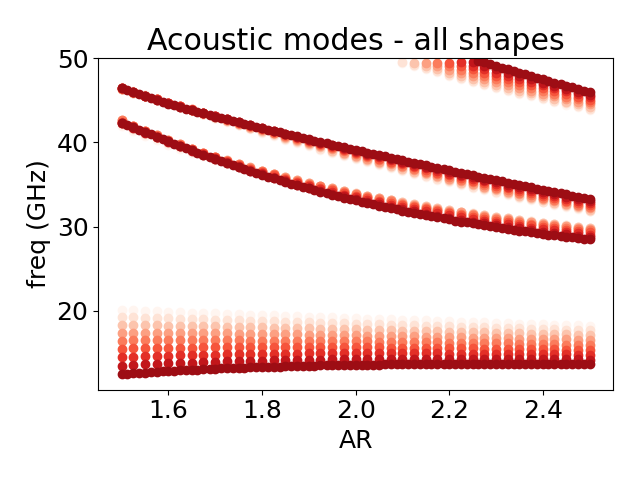

In [8]:
fig, ax = plt.subplots()

for key in Spectra_data :
    spectra = Spectra_data[key]
    


    for kkey in spectra :
        single_ND_modes = spectra[kkey]
        #print(np.sum(spectra['projection']))
        #print(spectra['eigen_freq'][np.argmax(spectra['projection'])])
        ax.scatter(single_ND_modes['AR']*np.ones(np.size(single_ND_modes['modes']['f'])), single_ND_modes['modes']['f'], color=Colors[key])

plt.title('Acoustic modes - all shapes')
plt.ylim(top=50)
plt.xlabel('AR')
plt.ylabel('freq (GHz)')
plt.tight_layout()

dir_to_save = dir_root  + r'\Figures'
if not(os.path.exists(dir_to_save)) :
    os.mkdir(dir_to_save)
os.chdir(dir_to_save)
plt.savefig('freq(AR) - all shapes.pdf')
plt.savefig('freq(AR) - all shapes.png')

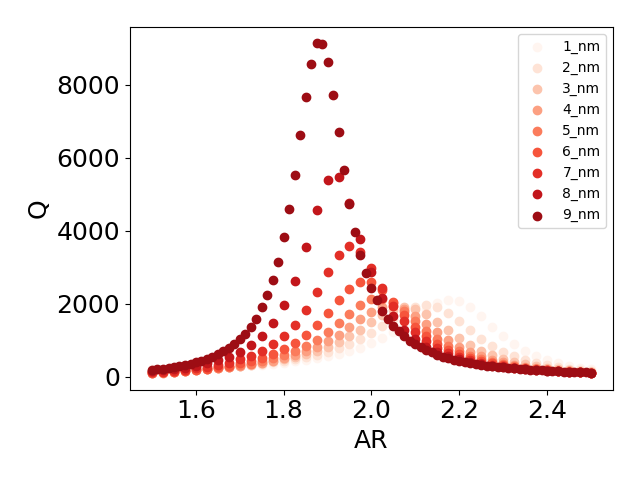

In [9]:
AR_min = 1
AR_max = 3

fig, ax = plt.subplots()



for key in Spectra_data :
    spectra = Spectra_data[key]
    AR, Q = get_max_Q(spectra, freq_low_func=Boundary_func[key][0], freq_high_func=Boundary_func[key][1],AR_min=AR_min, AR_max=AR_max)
    ax.scatter(AR, Q, color=Colors[key], label = key)


plt.xlabel('AR')
plt.ylabel('Q')
plt.legend(fontsize=10)
plt.tight_layout()

C:\Users\nberr\AppData\Local\Temp\ipykernel_10980\1704732299.py:5: RuntimeWarning:

More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.



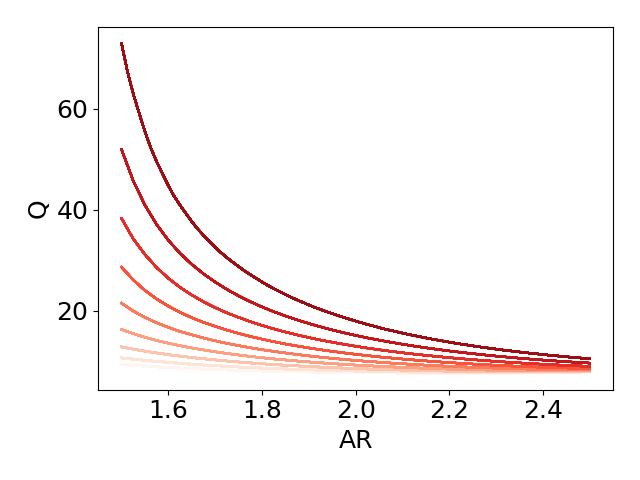

In [10]:


AR_all_shapes = {}
Q_all_shapes = {}
Freq_all_shapes = {}

fig, ax = plt.subplots()

for key in Spectra_data :
    spectra = Spectra_data[key]
    mode_dic = Modes_dic[key]


    get_Q_specific_bands_v2(spectra, freq_low_func=Boundary_func[key][0], freq_high_func=Boundary_func[key][1],Mode_dic=mode_dic, AR_min=AR_min, AR_max=AR_max)
    
    for kkey in spectra :
        try :
            #ax.scatter(spectra[kkey]['AR'], spectra[kkey]['specific_modes']['1']['Q'], color=Colors[key], marker ='v')
            pass
        except :
            pass


        try :
            #ax.scatter(spectra[kkey]['AR'], spectra[kkey]['specific_modes']['2']['Q'], color=Colors[key])
            pass
        except :
            pass
        
        ax.plot([spectra[kkey]['AR'] for kkey in spectra], [spectra[kkey]['specific_modes']['1']['Q'] for kkey in spectra], color=Colors[key])
plt.xlabel('AR')
plt.ylabel('Q')
#plt.legend(fontsize=10)
plt.tight_layout()


dir_to_save = dir_root  + r'\Figures'
if not(os.path.exists(dir_to_save)) :
    os.mkdir(dir_to_save)
os.chdir(dir_to_save)
plt.savefig('Q(AR) - all shapes.pdf')
plt.savefig('Q(AR) - all shapes.png')

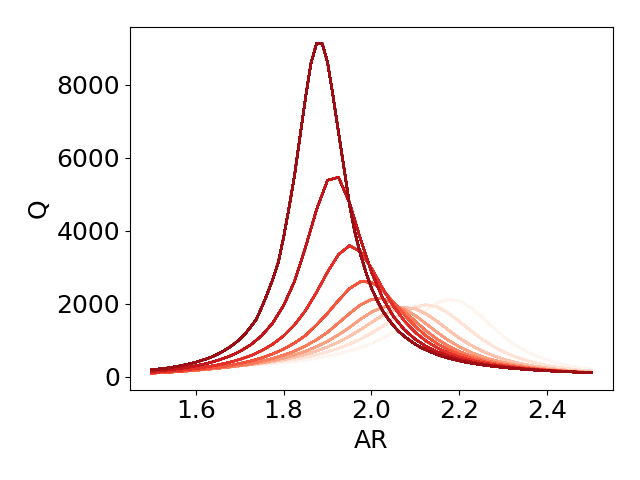

In [11]:

AR_all_shapes = {}
Q_all_shapes = {}
Freq_all_shapes = {}

fig, ax = plt.subplots()

for key in Spectra_data :
    spectra = Spectra_data[key]
    mode_dic = Modes_dic[key]
    get_Q_specific_bands_v2(spectra, freq_low_func=Boundary_func[key][0], freq_high_func=Boundary_func[key][1],Mode_dic=mode_dic, AR_min=AR_min, AR_max=AR_max)
    for kkey in spectra :
        try :
            #ax.scatter(spectra[kkey]['AR'], spectra[kkey]['specific_modes']['1']['Q'], color=Colors[key], marker ='v')
            pass
        except :
            pass


        try :
            #ax.scatter(spectra[kkey]['AR'], spectra[kkey]['specific_modes']['2']['Q'], color=Colors[key])
            pass
        except :
            pass
        ax.plot([spectra[kkey]['AR'] for kkey in spectra], [spectra[kkey]['specific_modes']['2']['Q'] for kkey in spectra], color=Colors[key])
plt.xlabel('AR')
plt.ylabel('Q')
#plt.legend(fontsize=10)
plt.tight_layout()


dir_to_save = dir_root  + r'\Figures'
if not(os.path.exists(dir_to_save)) :
    os.mkdir(dir_to_save)
os.chdir(dir_to_save)
plt.savefig('Q(AR) - all shapes.pdf')
plt.savefig('Q(AR) - all shapes.png')

## Save data

In [12]:
if 1 :
    for key in Spectra_data :
        spectra = Spectra_data[key]


        dir_to_save = dir_root + r'\\' + key + r'\Treated data'
        save_Q_with_AR_to_csv(dir_to_save, 'Selected acoustic modes', Q_all_shapes[key], AR_all_shapes[key], Freq_all_shapes[key])
        save_freq_with_AR_to_csv(dir_to_save, 'Q and freq', spectra)


KeyError: '1_nm'